In [11]:
import pandas as pd
import numpy as np
from sklearn.linear_model import LogisticRegression

# ── Einstellungen: pro Kategorie nur diese zwei Zeilen ändern ──
DATEI = r"C:\Users\ronsh\OneDrive\Desktop\MA\Daten\Open Play Fuss.xlsx"
NAME = 'Open Play – Fuss'     # nur für die Ausgabe

# 1. Daten laden (Excel-Datei vorher schliessen)
df = pd.read_excel(DATEI)
df = df.dropna(subset=['x (StatsBomb)', 'y (StatsBomb)']).copy()

# 2. Konstanten: StatsBomb misst in Yards (1 Einheit = 0.9144 m)
YARD = 0.9144
PFOSTEN_LINKS, PFOSTEN_RECHTS = 36, 44
TORBREITE = PFOSTEN_RECHTS - PFOSTEN_LINKS   # 8 Einheiten = 7.32 m

def distanz_winkel(x, y):
    x = np.asarray(x, float)
    y = np.asarray(y, float)
    dist = np.sqrt((120 - x)**2 + (40 - y)**2) * YARD
    d1 = np.sqrt((120 - x)**2 + (PFOSTEN_LINKS - y)**2)
    d2 = np.sqrt((120 - x)**2 + (PFOSTEN_RECHTS - y)**2)
    cos_a = ((d1**2 + d2**2 - TORBREITE**2) / (2 * d1 * d2)).clip(-1, 1)
    return dist, np.degrees(np.arccos(cos_a))

df['Distanz'], df['Winkel'] = distanz_winkel(df['x (StatsBomb)'], df['y (StatsBomb)'])
df['Distanz_x_Winkel'] = df['Distanz'] * df['Winkel']
merkmale = ['Distanz', 'Winkel', 'Distanz_x_Winkel']

# Kontrolle der Formeln
dk, wk = distanz_winkel([90], [34])
print(f"Kontrolle (90,34): Distanz {dk[0]:.2f} m, Winkel {wk[0]:.2f}°  (erwartet: 27.98 m, 14.62°)")


# 4. Regression
tor = df['Tor (1/0)']
m = LogisticRegression()
m.fit(df[merkmale], tor)
b0, (b1, b2, b3) = m.intercept_[0], m.coef_[0]

print("\n=== Betas ===")
print(f"β0 (Konstante):        {b0:.4f}")
print(f"β1 (Distanz):          {b1:.4f}")
print(f"β2 (Winkel):           {b2:.4f}")
print(f"β3 (Distanz x Winkel): {b3:.4f}")

# 5. xG direkt vom Modell (keine eingetippten Betas)
df['xG_eigenes_Modell'] = m.predict_proba(df[merkmale])[:, 1]
xg_me, xg_sb = df['xG_eigenes_Modell'], df['xG (StatsBomb)']
p = tor.mean()

print("\n=== VERGLEICH: Eigenes Modell vs. StatsBomb ===")
print(f"Durchschnitt xG (StatsBomb):      {xg_sb.mean():.4f}")
print(f"Durchschnitt xG (Eigenes Modell): {xg_me.mean():.4f}")
print(f"Echte Torquote:                   {p:.4f}")
print(f"\nTotal xG (StatsBomb):             {xg_sb.sum():.2f}")
print(f"Total xG (Eigenes Modell):        {xg_me.sum():.2f}")
print(f"Anzahl echte Tore:                {int(tor.sum())}")


# 6. Erste 10 Schüsse
print("\n=== ERSTE 10 SCHÜSSE ===")
print(df[['Spieler', 'Distanz', 'Winkel', 'xG (StatsBomb)', 'xG_eigenes_Modell', 'Tor (1/0)']]
      .head(10).round(4).to_string())

Kontrolle (90,34): Distanz 27.98 m, Winkel 14.62°  (erwartet: 27.98 m, 14.62°)

=== Betas ===
β0 (Konstante):        -1.1308
β1 (Distanz):          -0.1306
β2 (Winkel):           0.0234
β3 (Distanz x Winkel): 0.0011

=== VERGLEICH: Eigenes Modell vs. StatsBomb ===
Durchschnitt xG (StatsBomb):      0.0936
Durchschnitt xG (Eigenes Modell): 0.0980
Echte Torquote:                   0.0980

Total xG (StatsBomb):             825.10
Total xG (Eigenes Modell):        864.00
Anzahl echte Tore:                864

=== ERSTE 10 SCHÜSSE ===
                       Spieler  Distanz   Winkel  xG (StatsBomb)  xG_eigenes_Modell  Tor (1/0)
0       Borja Iglesias Quintas  17.0716  17.3658          0.0849             0.0672          0
1                 Granit Xhaka  21.4886  19.3195          0.0424             0.0460          0
2                  Adam Hložek  29.5096  13.9325          0.0176             0.0146          0
3    Alejandro Grimaldo García  11.4596  35.3335          0.1191             0.2042  

Open Play – Fuss: 8815 Schüsse, 864 Tore
Betas: -1.0806 [-0.1377  0.0247  0.0012]
Total xG StatsBomb: 825.1 | eigenes Modell: 864.0 | echte Tore: 864
Brier eigenes Modell: 0.0749 | StatsBomb: 0.0687


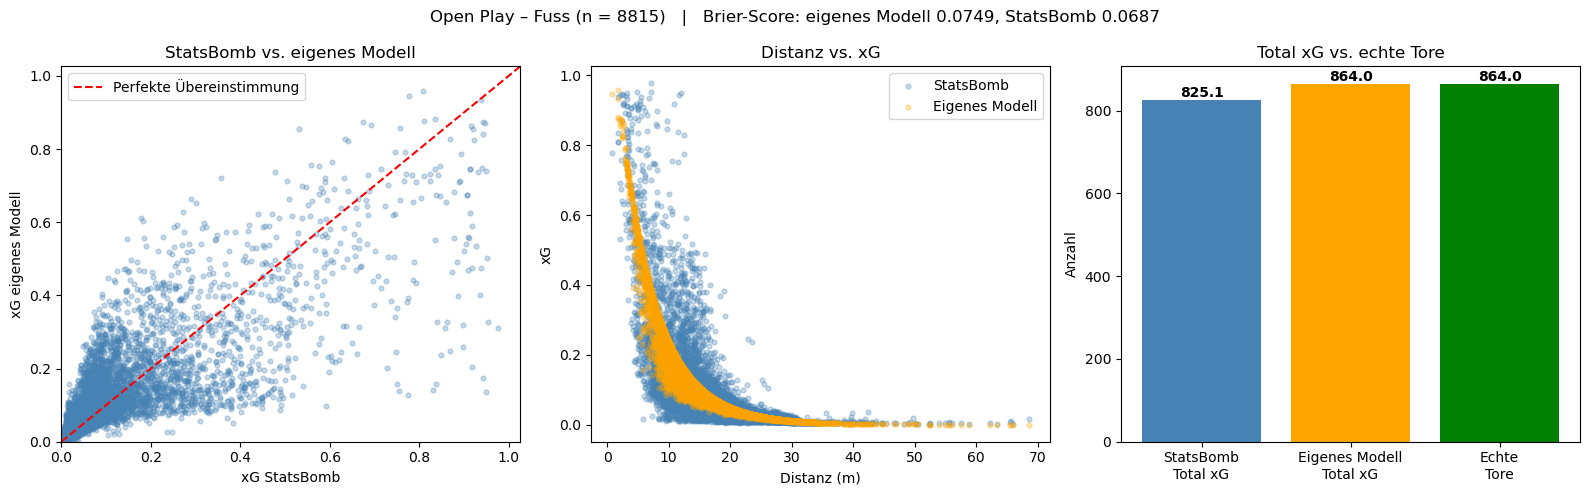

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression

# ── Einstellung: welche Kategorie? ──
# 'Open Play – Fuss', 'Open Play – Kopfball', 'Freistoss' oder 'Elfmeter'
KATEGORIE = 'Open Play – Fuss'

# 1. Daten laden (Excel-Datei vorher schliessen)
df = pd.read_excel(r'C:\Users\ronsh\OneDrive\Desktop\MA\StatsBomb_11301_Schuesse.xlsx')
df = df.dropna(subset=['x (StatsBomb)', 'y (StatsBomb)']).copy()

# 2. Distanz, Winkel, Interaktionsterm
x = df['x (StatsBomb)']
y = df['y (StatsBomb)']
df['Distanz'] = np.sqrt((120 - x)**2 + (40 - y)**2) * (105/120)
d1 = np.sqrt((120 - x)**2 + (36.34 - y)**2)
d2 = np.sqrt((120 - x)**2 + (43.66 - y)**2)
cos_a = ((d1**2 + d2**2 - 7.32**2) / (2 * d1 * d2)).clip(-1, 1)
df['Winkel'] = np.degrees(np.arccos(cos_a))
df['Distanz_x_Winkel'] = df['Distanz'] * df['Winkel']

# 3. Kategorie auswählen
masken = {
    'Open Play – Fuss':     (df['Typ'] == 'Open Play') & (df['Körperteil'] != 'Head'),
    'Open Play – Kopfball': (df['Typ'] == 'Open Play') & (df['Körperteil'] == 'Head'),
    'Freistoss':            (df['Typ'] == 'Free Kick'),
    'Elfmeter':             (df['Typ'] == 'Penalty'),
}
d = df[masken[KATEGORIE]].copy()

# 4. Modell fitten, xG direkt vom Modell
merkmale = ['Distanz', 'Winkel', 'Distanz_x_Winkel']
m = LogisticRegression()
m.fit(d[merkmale], d['Tor (1/0)'])
d['xG_eigenes_Modell'] = m.predict_proba(d[merkmale])[:, 1]

tor = d['Tor (1/0)']
xg_me = d['xG_eigenes_Modell']
xg_sb = d['xG (StatsBomb)']
brier_me = ((xg_me - tor)**2).mean()
brier_sb = ((xg_sb - tor)**2).mean()

print(f"{KATEGORIE}: {len(d)} Schüsse, {int(tor.sum())} Tore")
print("Betas:", round(m.intercept_[0], 4), m.coef_[0].round(4))
print(f"Total xG StatsBomb: {xg_sb.sum():.1f} | eigenes Modell: {xg_me.sum():.1f} | echte Tore: {int(tor.sum())}")
print(f"Brier eigenes Modell: {brier_me:.4f} | StatsBomb: {brier_sb:.4f}")

# 5. Grafiken
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# Grafik 1: StatsBomb vs. eigenes Modell
grenze = max(xg_sb.max(), xg_me.max()) * 1.05
axes[0].scatter(xg_sb, xg_me, alpha=0.3, s=12, color='steelblue')
axes[0].plot([0, grenze], [0, grenze], 'r--', label='Perfekte Übereinstimmung')
axes[0].set_xlim(0, grenze)
axes[0].set_ylim(0, grenze)
axes[0].set_xlabel('xG StatsBomb')
axes[0].set_ylabel('xG eigenes Modell')
axes[0].set_title('StatsBomb vs. eigenes Modell')
axes[0].legend()

# Grafik 2: Distanz vs. xG
axes[1].scatter(d['Distanz'], xg_sb, alpha=0.3, s=12, color='steelblue', label='StatsBomb')
axes[1].scatter(d['Distanz'], xg_me, alpha=0.3, s=12, color='orange', label='Eigenes Modell')
axes[1].set_xlabel('Distanz (m)')
axes[1].set_ylabel('xG')
axes[1].set_title('Distanz vs. xG')
axes[1].legend()

# Grafik 3: Total xG vs. echte Tore
labels = ['StatsBomb\nTotal xG', 'Eigenes Modell\nTotal xG', 'Echte\nTore']
werte = [xg_sb.sum(), xg_me.sum(), tor.sum()]
balken = axes[2].bar(labels, werte, color=['steelblue', 'orange', 'green'])
for b, w in zip(balken, werte):
    axes[2].text(b.get_x() + b.get_width()/2, b.get_height() + max(werte)*0.01,
                 f'{w:.1f}', ha='center', fontweight='bold')
axes[2].set_ylabel('Anzahl')
axes[2].set_title('Total xG vs. echte Tore')

fig.suptitle(f'{KATEGORIE} (n = {len(d)})   |   Brier-Score: eigenes Modell {brier_me:.4f}, StatsBomb {brier_sb:.4f}',
             fontsize=12)
plt.tight_layout()

dateiname = KATEGORIE.replace(' – ', '_').replace(' ', '_')
plt.savefig(rf'C:\Users\ronsh\OneDrive\Desktop\MA\Vergleich_{dateiname}.png', dpi=150, bbox_inches='tight')
plt.show()

Fuss: 8805 Schüsse, 864 Tore
Kopfball: 1845 Schüsse, 178 Tore


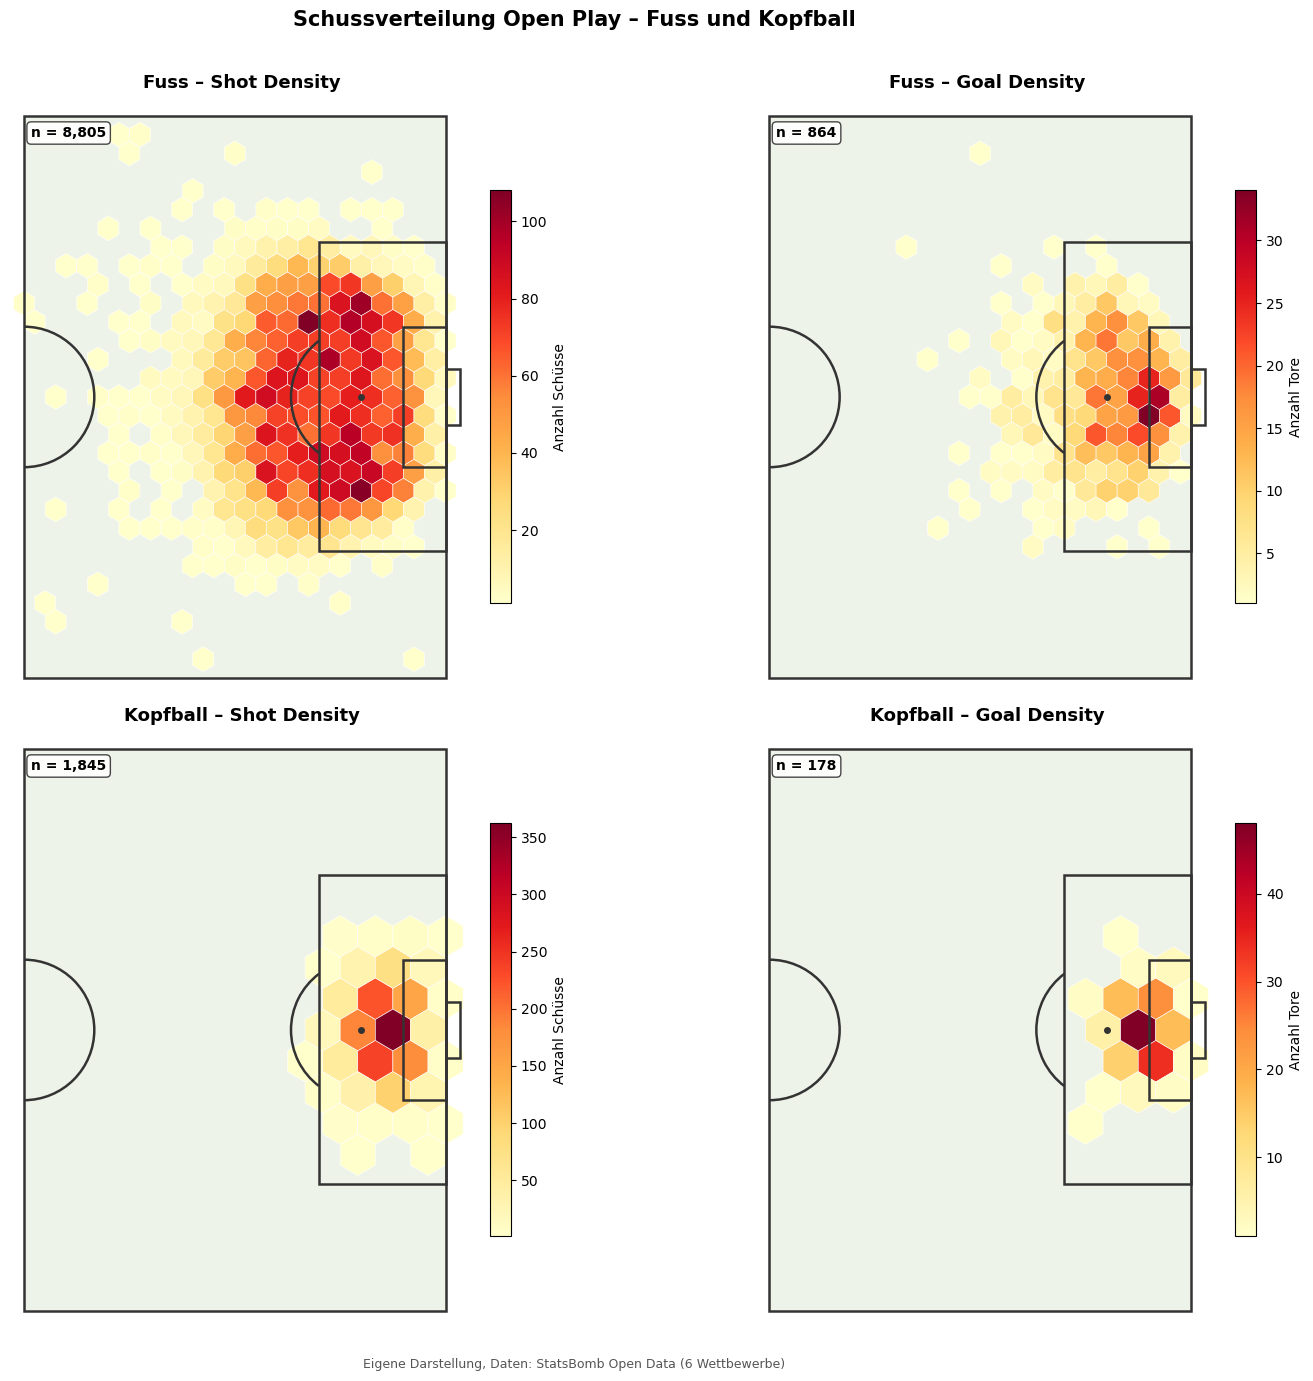

In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patches

# ── Einstellungen ──
GRIDSIZE = {'Fuss': 20, 'Kopfball': 12}   # kleiner = grössere Hexagone

# 1. Daten laden (Excel-Datei vorher schliessen)
df = pd.read_excel(r'C:\Users\ronsh\OneDrive\Desktop\MA\StatsBomb_11301_Schuesse.xlsx')
df = df.dropna(subset=['x (StatsBomb)', 'y (StatsBomb)']).copy()

# 2. Open Play, getrennt nach Körperteil, nur Angriffshälfte
op = df[(df['Typ'] == 'Open Play') & (df['x (StatsBomb)'] >= 60)]
gruppen = {
    'Fuss':     op[op['Körperteil'] != 'Head'],
    'Kopfball': op[op['Körperteil'] == 'Head'],
}
for name, g in gruppen.items():
    print(f"{name}: {len(g)} Schüsse, {int(g['Tor (1/0)'].sum())} Tore")

# 3. Halbfeld zeichnen
def zeichne_halbfeld(ax):
    c, lw = '#333333', 1.8
    ax.add_patch(patches.Rectangle((60, 0), 60, 80, facecolor='#eef3ea', edgecolor='none', zorder=0))
    ax.add_patch(patches.Rectangle((60, 0), 60, 80, fill=False, edgecolor=c, linewidth=lw, zorder=5))
    ax.add_patch(patches.Rectangle((102, 18), 18, 44, fill=False, edgecolor=c, linewidth=lw, zorder=5))
    ax.add_patch(patches.Rectangle((114, 30), 6, 20, fill=False, edgecolor=c, linewidth=lw, zorder=5))
    ax.add_patch(patches.Rectangle((120, 36), 2, 8, fill=False, edgecolor=c, linewidth=lw, zorder=5))
    ax.add_patch(patches.Arc((60, 40), 20, 20, theta1=270, theta2=90, color=c, linewidth=lw, zorder=5))
    ax.add_patch(patches.Arc((108, 40), 20, 20, theta1=127, theta2=233, color=c, linewidth=lw, zorder=5))
    ax.plot(108, 40, 'o', color=c, markersize=4, zorder=6)

# 4. Grafik: 2 Zeilen (Fuss, Kopfball) x 2 Spalten (Schüsse, Tore)
fig, axes = plt.subplots(2, 2, figsize=(16, 14))
fig.patch.set_facecolor('white')

for zeile, (name, g) in enumerate(gruppen.items()):
    gx = GRIDSIZE[name]
    gy = int(round(gx * 80 / (60 * np.sqrt(3))))
    tore = g[g['Tor (1/0)'] == 1]

    for spalte, (daten, titel, label) in enumerate([
        (g,    f'{name} – Shot Density', 'Anzahl Schüsse'),
        (tore, f'{name} – Goal Density', 'Anzahl Tore'),
    ]):
        ax = axes[zeile, spalte]
        zeichne_halbfeld(ax)
        hb = ax.hexbin(
            daten['x (StatsBomb)'], daten['y (StatsBomb)'],
            gridsize=(gx, gy), extent=(60, 120, 0, 80),
            cmap='YlOrRd', mincnt=1,
            edgecolors='white', linewidths=0.4, zorder=3
        )
        fig.colorbar(hb, ax=ax, shrink=0.7, pad=0.02, label=label)
        ax.text(61, 77, f'n = {len(daten):,}', fontsize=10, fontweight='bold', zorder=7,
                bbox=dict(boxstyle='round,pad=0.3', facecolor='white', edgecolor='#333333', alpha=0.9))
        ax.set_xlim(58, 124)
        ax.set_ylim(-2, 82)
        ax.set_aspect('equal')
        ax.axis('off')
        ax.set_title(titel, fontsize=13, fontweight='bold', pad=10)

fig.suptitle('Schussverteilung Open Play – Fuss und Kopfball', fontsize=15, fontweight='bold')
fig.text(0.5, 0.01, 'Eigene Darstellung, Daten: StatsBomb Open Data (6 Wettbewerbe)',
         ha='center', fontsize=9, color='#555555')
plt.tight_layout(rect=[0, 0.03, 1, 0.97])

plt.savefig(r'C:\Users\ronsh\OneDrive\Desktop\MA\Hexbin_Fuss_Kopfball.png', dpi=150, bbox_inches='tight')
plt.show()

Spiele in Training und Test gleichzeitig: 0 (erwartet: 0)

=== Open Play – Fuss ===
Training: 8815 Schüsse, 864 Tore (Torquote 0.0980)
Test:     7375 Schüsse, 674 Tore (Torquote 0.0914)
Betas (Training): -1.1308 [-0.1306  0.0234  0.0011]

Ø xG StatsBomb:       0.0891
Ø xG eigenes Modell:  0.0938
Echte Torquote (Test): 0.0914

Total xG StatsBomb:      656.9
Total xG eigenes Modell: 691.4
Echte Tore:              674

Brier eigenes Modell:        0.0737
Brier StatsBomb:             0.0673
Brier konstante Torquote:    0.0831
Verbesserung ggü. konstant:  eigenes Modell 11.2 %, StatsBomb 19.0 %


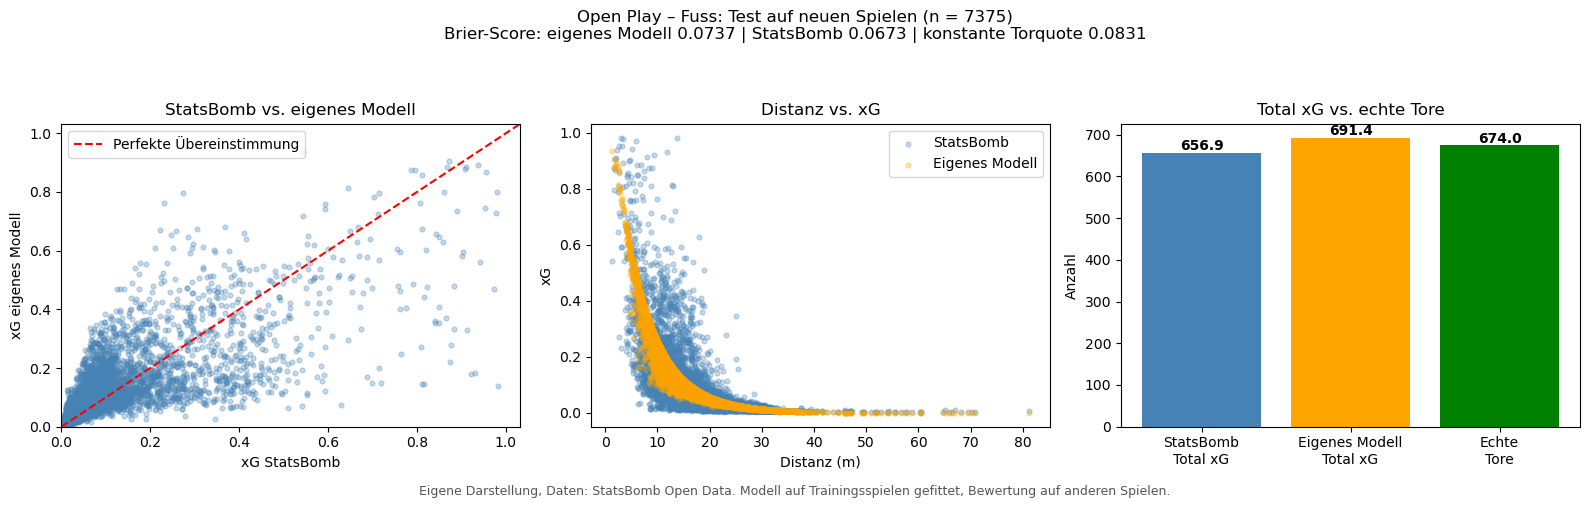

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression

# ── Einstellungen: pro Kategorie nur diese zwei Zeilen ändern ──
TRAIN_DATEI = r"C:\Users\ronsh\OneDrive\Desktop\MA\Daten\Open Play Fuss.xlsx"   # deine Datei der Kategorie
TEST_DATEI  = r"C:\Users\ronsh\OneDrive\Desktop\MA\Daten\Test Daten Open Play Fuss.xlsx"
NAME = 'Open Play – Fuss'   # 'Open Play – Kopfball', 'Freistoss' oder 'Elfmeter'

# 1. Konstanten: StatsBomb misst in Yards (1 Einheit = 0.9144 m)
YARD = 0.9144
PFOSTEN_LINKS, PFOSTEN_RECHTS = 36, 44
TORBREITE = PFOSTEN_RECHTS - PFOSTEN_LINKS

def distanz_winkel(x, y):
    x = np.asarray(x, float)
    y = np.asarray(y, float)
    dist = np.sqrt((120 - x)**2 + (40 - y)**2) * YARD
    d1 = np.sqrt((120 - x)**2 + (PFOSTEN_LINKS - y)**2)
    d2 = np.sqrt((120 - x)**2 + (PFOSTEN_RECHTS - y)**2)
    cos_a = ((d1**2 + d2**2 - TORBREITE**2) / (2 * d1 * d2)).clip(-1, 1)
    return dist, np.degrees(np.arccos(cos_a))

def vorbereiten(df):
    df = df.dropna(subset=['x (StatsBomb)', 'y (StatsBomb)']).copy()
    df['Distanz'], df['Winkel'] = distanz_winkel(df['x (StatsBomb)'], df['y (StatsBomb)'])
    df['Distanz_x_Winkel'] = df['Distanz'] * df['Winkel']
    return df

merkmale = ['Distanz', 'Winkel', 'Distanz_x_Winkel']

# 2. Daten laden (Excel-Dateien vorher schliessen)
train = vorbereiten(pd.read_excel(TRAIN_DATEI))
test_alle = vorbereiten(pd.read_excel(TEST_DATEI))

masken = {
    'Open Play – Fuss':     (test_alle['Typ'] == 'Open Play') & (test_alle['Körperteil'] != 'Head'),
    'Open Play – Kopfball': (test_alle['Typ'] == 'Open Play') & (test_alle['Körperteil'] == 'Head'),
    'Freistoss':            (test_alle['Typ'] == 'Free Kick'),
    'Elfmeter':             (test_alle['Typ'] == 'Penalty'),
}
test = test_alle[masken[NAME]].copy()

# Kontrolle: keine Spiele in beiden Datensätzen
if {'Liga', 'Spiel'} <= set(train.columns):
    spiele_train = set(zip(train['Liga'], train['Spiel']))
    spiele_test = set(zip(test_alle['Liga'], test_alle['Spiel']))
    print("Spiele in Training und Test gleichzeitig:", len(spiele_train & spiele_test), "(erwartet: 0)")

# 3. Fitten nur auf dem Training, xG für die Testschüsse vom Modell
m = LogisticRegression()
m.fit(train[merkmale], train['Tor (1/0)'])
test['xG_eigenes_Modell'] = m.predict_proba(test[merkmale])[:, 1]

tor = test['Tor (1/0)']
xg_me, xg_sb = test['xG_eigenes_Modell'], test['xG (StatsBomb)']
p_train = train['Tor (1/0)'].mean()

brier_me = ((xg_me - tor)**2).mean()
brier_sb = ((xg_sb - tor)**2).mean()
brier_const = ((p_train - tor)**2).mean()   # Torquote aus dem Training für alle Testschüsse

# 4. Zahlen
print(f"\n=== {NAME} ===")
print(f"Training: {len(train)} Schüsse, {int(train['Tor (1/0)'].sum())} Tore (Torquote {p_train:.4f})")
print(f"Test:     {len(test)} Schüsse, {int(tor.sum())} Tore (Torquote {tor.mean():.4f})")
print("Betas (Training):", round(m.intercept_[0], 4), m.coef_[0].round(4))

print(f"\nØ xG StatsBomb:       {xg_sb.mean():.4f}")
print(f"Ø xG eigenes Modell:  {xg_me.mean():.4f}")
print(f"Echte Torquote (Test): {tor.mean():.4f}")
print(f"\nTotal xG StatsBomb:      {xg_sb.sum():.1f}")
print(f"Total xG eigenes Modell: {xg_me.sum():.1f}")
print(f"Echte Tore:              {int(tor.sum())}")

print(f"\nBrier eigenes Modell:        {brier_me:.4f}")
print(f"Brier StatsBomb:             {brier_sb:.4f}")
print(f"Brier konstante Torquote:    {brier_const:.4f}")
print(f"Verbesserung ggü. konstant:  eigenes Modell {100*(1-brier_me/brier_const):.1f} %, "
      f"StatsBomb {100*(1-brier_sb/brier_const):.1f} %")

# 5. Grafiken (nur Testdaten)
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

grenze = max(xg_sb.max(), xg_me.max()) * 1.05
axes[0].scatter(xg_sb, xg_me, alpha=0.3, s=12, color='steelblue')
axes[0].plot([0, grenze], [0, grenze], 'r--', label='Perfekte Übereinstimmung')
axes[0].set_xlim(0, grenze); axes[0].set_ylim(0, grenze)
axes[0].set_xlabel('xG StatsBomb'); axes[0].set_ylabel('xG eigenes Modell')
axes[0].set_title('StatsBomb vs. eigenes Modell'); axes[0].legend()

axes[1].scatter(test['Distanz'], xg_sb, alpha=0.3, s=12, color='steelblue', label='StatsBomb')
axes[1].scatter(test['Distanz'], xg_me, alpha=0.3, s=12, color='orange', label='Eigenes Modell')
axes[1].set_xlabel('Distanz (m)'); axes[1].set_ylabel('xG')
axes[1].set_title('Distanz vs. xG'); axes[1].legend()

labels = ['StatsBomb\nTotal xG', 'Eigenes Modell\nTotal xG', 'Echte\nTore']
werte = [xg_sb.sum(), xg_me.sum(), tor.sum()]
balken = axes[2].bar(labels, werte, color=['steelblue', 'orange', 'green'])
for b, w in zip(balken, werte):
    axes[2].text(b.get_x() + b.get_width()/2, b.get_height() + max(werte)*0.01,
                 f'{w:.1f}', ha='center', fontweight='bold')
axes[2].set_ylabel('Anzahl'); axes[2].set_title('Total xG vs. echte Tore')

fig.suptitle(f'{NAME}: Test auf neuen Spielen (n = {len(test)})\n'
             f'Brier-Score: eigenes Modell {brier_me:.4f} | StatsBomb {brier_sb:.4f} | '
             f'konstante Torquote {brier_const:.4f}', fontsize=12)
fig.text(0.5, 0.01, 'Eigene Darstellung, Daten: StatsBomb Open Data. Modell auf Trainingsspielen gefittet, '
         'Bewertung auf anderen Spielen.', ha='center', fontsize=9, color='#555555')
plt.tight_layout(rect=[0, 0.03, 1, 0.92])

dateiname = NAME.replace(' – ', '_').replace(' ', '_')
plt.savefig(rf'C:\Users\ronsh\OneDrive\Desktop\MA\Test_{dateiname}.png', dpi=150, bbox_inches='tight')
plt.show()